# Classification Lab (Decision Trees)
Create your own majority voting based on the WINE dataset!

In [34]:
import pandas as pd

from sklearn import datasets
from sklearn import tree
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Load and prepare data set

Load the wine dataset!

In [35]:
#load the sklearn wine dataset 
wine = datasets.load_wine(return_X_y=False)

Create a data frame with the wine dataset and show its content

In [36]:
#Create a data frame with the features of the wine dataset
df=pd.DataFrame(wine.data,columns=wine.feature_names)

#Add the label of the wine data set to your data frame
df['label']=wine.target

#shuffle data frame
df=df.sample(frac=1)

#Show data frame content and check the shape of your dataframe (number of rows and columns)
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,label
107,12.72,1.75,2.28,22.5,84.0,1.38,1.76,0.48,1.63,3.30,0.88,2.42,488.0,1
60,12.33,1.10,2.28,16.0,101.0,2.05,1.09,0.63,0.41,3.27,1.25,1.67,680.0,1
134,12.51,1.24,2.25,17.5,85.0,2.00,0.58,0.60,1.25,5.45,0.75,1.51,650.0,2
95,12.47,1.52,2.20,19.0,162.0,2.50,2.27,0.32,3.28,2.60,1.16,2.63,937.0,1
58,13.72,1.43,2.50,16.7,108.0,3.40,3.67,0.19,2.04,6.80,0.89,2.87,1285.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,14.22,1.70,2.30,16.3,118.0,3.20,3.00,0.26,2.03,6.38,0.94,3.31,970.0,0
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
81,12.72,1.81,2.20,18.8,86.0,2.20,2.53,0.26,1.77,3.90,1.16,3.14,714.0,1
19,13.64,3.10,2.56,15.2,116.0,2.70,3.03,0.17,1.66,5.10,0.96,3.36,845.0,0


# Explore data set

Show descriptive statistics of your data frame

In [18]:
#Show descriptive statistics of your data frame (see PANDAS1 lab)
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,label
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Create a correlations heat map using the wine data frame

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

#calculate correlations between all features of your data frame (see Exploration lab)
corr = df.corr()

# Displaying correlations as a heatmap / correlation matrix 
corr.style.background_gradient(cmap ='coolwarm')

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,label
alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720,-0.328222
malic_acid,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011,0.437776
ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626,-0.049643
alcalinity_of_ash,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597,0.517859
magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351,-0.209179
total_phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115,-0.719163
flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193,-0.847498
nonflavanoid_phenols,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385,0.489109
proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417,-0.499130
color_intensity,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100,0.265668


Create histograms for the first 6 features using the dataframe method "hist"

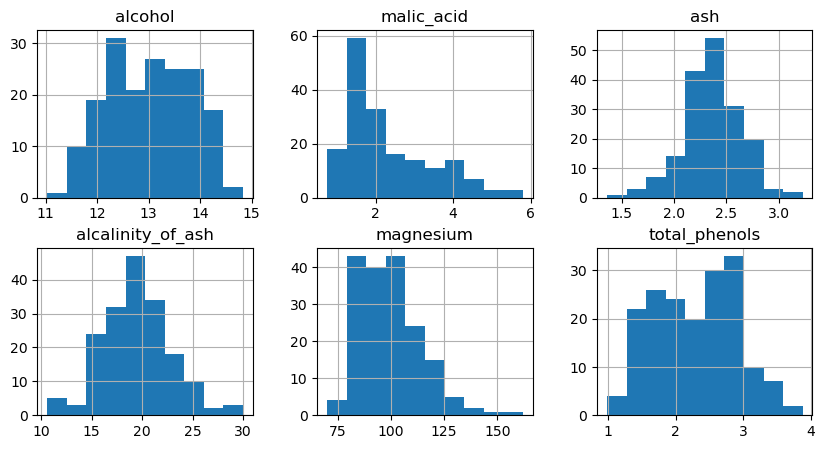

In [20]:
#Create a new data frame, which only includes the first 6 features of the wine dataset
df_first_six_features = df.iloc[:,:6]

#Create histograms for the first 6 features using the dataframe method "hist"
#use figsize=(10,5) and a layout of 2 rows and 3 columns
hist = df_first_six_features.hist(figsize=(10,5), layout=(2,3))

# Model Building

Split data into training and test data (120 training examples)

In [28]:
num_training_examples=120
num_features=13

#Training Data
train_features=df.iloc[:num_training_examples,:num_features]
train_labels=df.iloc[:num_training_examples,num_features]

#Test Data (the remaining examples)
#Add lines of code to create test data (features and labels)
test_features=df.iloc[num_training_examples:,:num_features]
test_labels=df.iloc[num_training_examples:,num_features]

test_features
#test_labels

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
165,13.73,4.36,2.26,22.5,88.0,1.28,0.47,0.52,1.15,6.62,0.780,1.75,520.0
154,12.58,1.29,2.10,20.0,103.0,1.48,0.58,0.53,1.40,7.60,0.580,1.55,640.0
112,11.76,2.68,2.92,20.0,103.0,1.75,2.03,0.60,1.05,3.80,1.230,2.50,607.0
30,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.190,2.71,1285.0
36,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.090,2.78,880.0
33,13.76,1.53,2.70,19.5,132.0,2.95,2.74,0.50,1.35,5.40,1.250,3.00,1235.0
159,13.48,1.67,2.64,22.5,89.0,2.60,1.10,0.52,2.29,11.75,0.570,1.78,620.0
88,11.64,2.06,2.46,21.6,84.0,1.95,1.69,0.48,1.35,2.80,1.000,2.75,680.0
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.040,3.92,1065.0
29,14.02,1.68,2.21,16.0,96.0,2.65,2.33,0.26,1.98,4.70,1.040,3.59,1035.0


Initialize and fit a classification tree, gradient boosted tree and bagging tree model, using the training data

In [22]:
dt = tree.DecisionTreeClassifier(random_state=0)
dt.fit(train_features, train_labels)

gbt = GradientBoostingClassifier(n_estimators=100, max_depth=4, learning_rate=1.0,random_state=0)
gbt.fit(train_features, train_labels)

bagt= BaggingClassifier(tree.DecisionTreeClassifier(),
                        n_estimators=10, random_state=0)
bagt.fit(train_features, train_labels)

BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=0)

# Model application to test data

Create three seperate predictions for your test features and append them in a list of lists

In [23]:
#create predictions for test data using the three decision tree models
bagt_predict=bagt.predict(test_features)
gbt_predict=gbt.predict(test_features)
dt_predict=dt.predict(test_features)

bagt_predict

array([2, 2, 1, 0, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 1, 0, 0, 2, 1, 0, 1, 1,
       1, 0, 0, 1, 0, 2, 1, 0, 1, 2, 2, 1, 0, 0, 0, 2, 2, 1, 0, 2, 2, 1,
       0, 1, 2, 1, 1, 1, 0, 0, 0, 2, 0, 2, 0, 0])

In [24]:
#initialize a list for your prediction values y_pred
y_pred= []

#store results of each of the three predictions in list of lists
for i in range(0,test_features.shape[0]):
        y_pred2=[]
        y_pred2.append(bagt_predict[i])
        y_pred2.append(gbt_predict[i]) 
        y_pred2.append(dt_predict[i])
        
        y_pred.append(y_pred2)

#Show content of y_pred        
y_pred

[[2, 2, 2],
 [2, 2, 2],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [0, 0, 0],
 [2, 2, 2],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [0, 0, 0],
 [2, 2, 2],
 [1, 1, 1],
 [1, 1, 1],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [2, 1, 2],
 [1, 1, 1],
 [0, 0, 0],
 [1, 1, 1],
 [1, 1, 1],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [1, 1, 1],
 [0, 0, 0],
 [2, 2, 1],
 [1, 1, 1],
 [0, 0, 0],
 [1, 1, 1],
 [2, 2, 2],
 [2, 2, 2],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [0, 0, 0],
 [2, 2, 2],
 [2, 2, 2],
 [1, 1, 0],
 [0, 0, 0],
 [2, 2, 2],
 [2, 2, 1],
 [1, 1, 1],
 [0, 0, 0],
 [1, 1, 1],
 [2, 2, 2],
 [1, 1, 1],
 [1, 1, 1],
 [1, 1, 1],
 [0, 0, 0],
 [0, 0, 0],
 [0, 1, 1],
 [2, 2, 2],
 [0, 0, 0],
 [2, 2, 2],
 [0, 0, 0],
 [0, 0, 1]]

Loop y_pred and use the most_frequent function to define the most frequent class

In [25]:
#function which returns most frequent value of a list
def most_frequent(List): 
    return max(set(List), key = List.count) 

for i in range(0,len(y_pred)):
    #use the most_frequent method for a majority voting and print the result
    most_frequent_class=most_frequent(y_pred[i])
    print("Most frequent class for test example",i,"is: ",most_frequent_class)

Most frequent class for test example 0 is:  2
Most frequent class for test example 1 is:  2
Most frequent class for test example 2 is:  1
Most frequent class for test example 3 is:  0
Most frequent class for test example 4 is:  0
Most frequent class for test example 5 is:  0
Most frequent class for test example 6 is:  2
Most frequent class for test example 7 is:  1
Most frequent class for test example 8 is:  0
Most frequent class for test example 9 is:  0
Most frequent class for test example 10 is:  0
Most frequent class for test example 11 is:  2
Most frequent class for test example 12 is:  1
Most frequent class for test example 13 is:  1
Most frequent class for test example 14 is:  1
Most frequent class for test example 15 is:  0
Most frequent class for test example 16 is:  0
Most frequent class for test example 17 is:  2
Most frequent class for test example 18 is:  1
Most frequent class for test example 19 is:  0
Most frequent class for test example 20 is:  1
Most frequent class for

# Results visualization

In [26]:
#create a list of all most_frequent_class values using a list comprehension
predicted_class = [most_frequent(y_pred[i]) for i in range(0,len(y_pred))]
#predicted_class

In [29]:
#Reconstruct test data in a data frame
df_test=pd.DataFrame(test_features)

#add actual label to data frame
df_test['actual_label']=test_labels

#add predicted (most frequent) label to data frame
df_test['predicted_label']=predicted_class

#show first 10 rows of df_test
df_test.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,actual_label,predicted_label
165,13.73,4.36,2.26,22.5,88.0,1.28,0.47,0.52,1.15,6.62,0.78,1.75,520.0,2,2
154,12.58,1.29,2.10,20.0,103.0,1.48,0.58,0.53,1.40,7.60,0.58,1.55,640.0,2,2
112,11.76,2.68,2.92,20.0,103.0,1.75,2.03,0.60,1.05,3.80,1.23,2.50,607.0,1,1
30,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0,0,0
36,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0,0,0
33,13.76,1.53,2.70,19.5,132.0,2.95,2.74,0.50,1.35,5.40,1.25,3.00,1235.0,0,0
159,13.48,1.67,2.64,22.5,89.0,2.60,1.10,0.52,2.29,11.75,0.57,1.78,620.0,2,2
88,11.64,2.06,2.46,21.6,84.0,1.95,1.69,0.48,1.35,2.80,1.00,2.75,680.0,1,1
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,0
29,14.02,1.68,2.21,16.0,96.0,2.65,2.33,0.26,1.98,4.70,1.04,3.59,1035.0,0,0


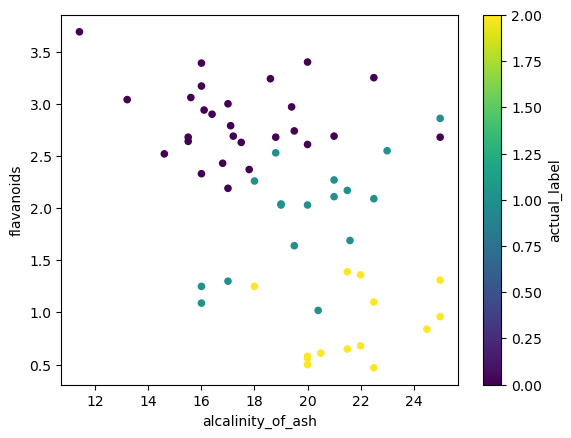

In [30]:
#plot actual label for test data in scatter plot using alcalinity_of_ash and flavanoids on x/y axis
# Scatter Plot
scatter = df_test.plot.scatter(x='alcalinity_of_ash', y='flavanoids', 
                           c='actual_label',colormap='viridis',sharex=False)

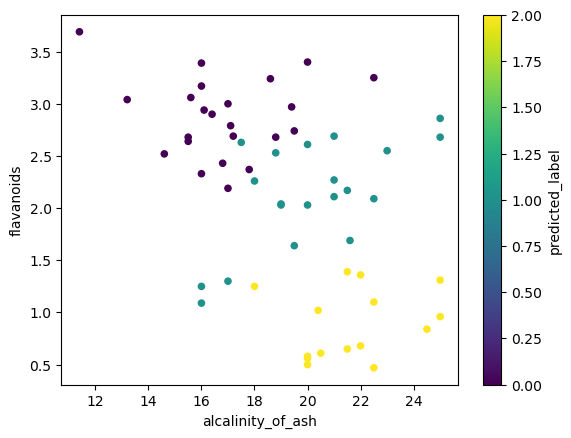

In [31]:
#plot predicted label for test data in scatter plot using alcalinity_of_ash and flavanoids on x/y axis
# Scatter Plot
scatter = df_test.plot.scatter(x='alcalinity_of_ash', y='flavanoids', 
                           c='predicted_label',colormap='viridis',sharex=False)

In [32]:
#Create a new feature 'correct_prediction' 
#with the values 1=correct prediction and 0=wrong prediction
df_test['correct_prediction']= df_test['actual_label'] == df_test['predicted_label']
df_test['correct_prediction']= df_test['correct_prediction'].astype(int)
#show first 10 rows of df_test['correct_prediction']
df_test['correct_prediction'].head(10)

165    1
154    1
112    1
30     1
36     1
33     1
159    1
88     1
0      1
29     1
Name: correct_prediction, dtype: int32

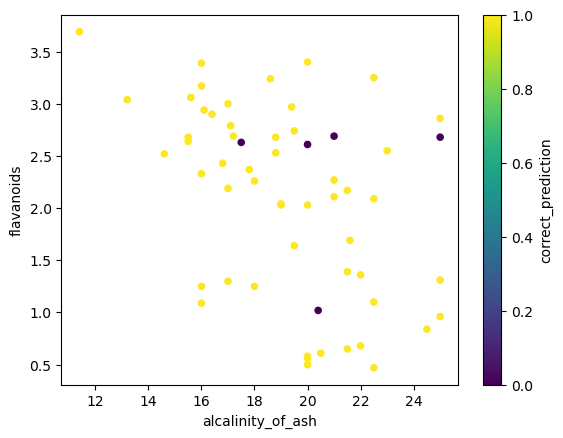

In [33]:
#plot 'correct_prediction' for test data in scatter plot using alcalinity_of_ash and flavanoids on x/y axis
# Scatter Plot
scatter = df_test.plot.scatter(x='alcalinity_of_ash', y='flavanoids', 
                           c='correct_prediction',colormap='viridis',sharex=False)